# 1: Importación de Librerías y Configuración
Importamos las librerías necesarias para el procesamiento de datos, visión artificial, machine learning y visualización gráfica.


In [ ]:
import os
import sys
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from ultralytics import YOLO
from sklearn.linear_model import LinearRegression
from sklearn.cluster import KMeans
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import seaborn as sns


# Definir la ruta base del proyecto
BASE_DIR=Path.cwd()
print("Librerías importadas correctamente.")
print("Ruta de trabajo:", BASE_DIR)


Librerías importadas correctamente.
Ruta de trabajo: c:\Programacion\Senati\MACHINE_LEARNING_DEEP_LEARNING


# 2: Preprocesamiento de Imágenes
Pasos fundamentales para preparar las imágenes antes de ingresarlas a los modelos.



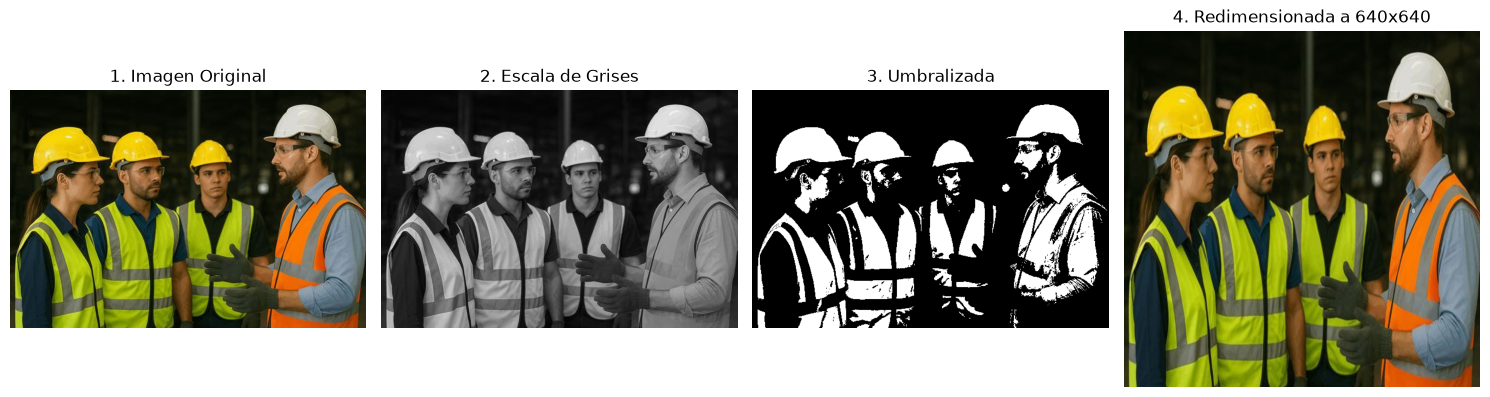

Preprocesamiento completado exitosamente.
Dimensiones originales: (416, 624, 3)
Rango normalizado - Minimo: 0.00392156862745098 | Maximo: 0.9725490196078431


In [ ]:
# Ruta de la imagen de prueba en el proyecto
ruta_img=BASE_DIR / "imagenes prueba" / "img3.jpg"

# 1. Cargamos la imagen original en color
imagen_bgr=cv2.imread(str(ruta_img))

if imagen_bgr is None:
    print("Error: No se pudo cargar la imagen en la ruta:", ruta_img)
else:
    imagen_rgb=cv2.cvtColor(imagen_bgr, cv2.COLOR_BGR2RGB)

    # 2. Convertimos a escala de grises
    imagen_gris=cv2.cvtColor(imagen_bgr, cv2.COLOR_BGR2GRAY)
    # 3. Normalizamos de pixeles en rango [0, 1]
    imagen_normalizada=imagen_gris / 255.0
    # 4. Umbralizamos para segmentar siluetas
    valor_ret, imagen_binaria=cv2.threshold(imagen_gris, 127, 255, cv2.THRESH_BINARY)
    # 5. Redimensionamos a formato estandar 640x640 para la red neuronal
    imagen_redimensionada=cv2.resize(imagen_rgb, (640, 640))

    # Visualizamos los pasos de preprocesamiento
    plt.figure(figsize=(15, 5))

    plt.subplot(1, 4, 1)
    plt.imshow(imagen_rgb)
    plt.title("1. Imagen Original")
    plt.axis("off")

    plt.subplot(1, 4, 2)
    plt.imshow(imagen_gris, cmap="gray")
    plt.title("2. Escala de Grises")
    plt.axis("off")

    plt.subplot(1, 4, 3)
    plt.imshow(imagen_binaria, cmap="gray")
    plt.title("3. Umbralizada")
    plt.axis("off")

    plt.subplot(1, 4, 4)
    plt.imshow(imagen_redimensionada)
    plt.title("4. Redimensionada a 640x640")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    print("Preprocesamiento completado exitosamente.")
    print("Dimensiones originales:", imagen_rgb.shape)
    print("Rango normalizado - Minimo:", np.min(imagen_normalizada), "| Maximo:", np.max(imagen_normalizada))


# 3: Arquitectura de la Red Neuronal (CNN)
Arquitectura de la red neuronal convolucional utilizada YOLOv8 nano:

| Componente | Descripción Técnica | Función en el Proyecto de EPPs |
| :--- | :--- | :--- |
| **Tipo de Red** | Red Neuronal Convolucional Profunda (CNN) | Detección multiobjeto y localización simultánea de cajas. |
| **Backbone** | CSPDarknet53 modificado con bloques **C2f** | Extrae mapas de características espaciales (bordes de cascos, colores de chalecos, formas humanas). |
| **Capas Convolucionales** | Convoluciones $3 \times 3$ con stride 2 | Reducen progresivamente la resolución espacial mientras aumentan la profundidad de canales. |
| **Capa de Pooling** | Agrupación de Pirámides Espaciales | Fusiona información visual a diferentes escalas
| **Neck** | Red de Agregación de Rutas (PAN-FPN) | Combina características de alta resolución con mapas semánticos profundos. |
| **Head** | Cabezal desacoplado | Separa la tarea de clasificación de la de regresión. |
| **Función de Activación** | **SiLU** (Unidad Lineal Sigmoide) | Aporta no-linealidad suave sin saturación, mejorando el flujo de gradientes frente a ReLU tradicional. |
| **Estrategia de Optimización**| **SGD / AdamW** con Momentum y decaimiento de Peso | Ajusta los pesos de la red minimizando el sobreajuste. |
| **Funciones de Pérdida** | CIoU Loss + DFL Loss "cajas" + BCE Loss "clases" | Permite precisión sub-píxel en el ajuste de las cajas delimitadoras. |



# 4: Implementación de Algoritmos Requeridos (Regresión y K-Means)
Implementación de **Regresión** y **K-Means** del proyecto **Deteccion EPPs**


### 4.1 Algoritmo de Regresión Lineal
Se analiza la relación entre las **horas de supervisión activa** en el proyecto y el **porcentaje de cumplimiento del uso de EPPs** por parte del personal operario.

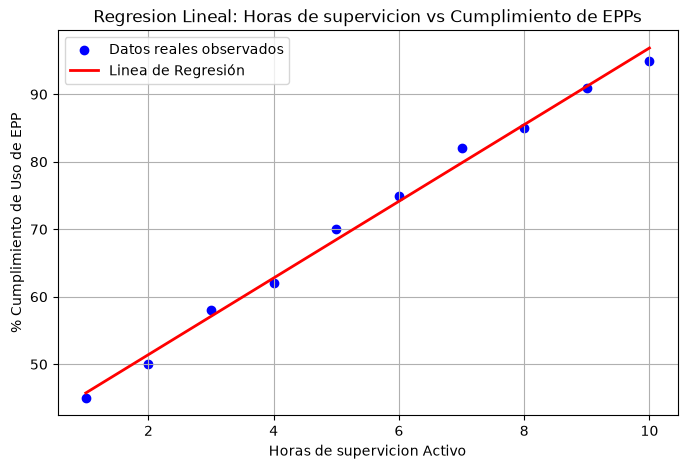

Pendiente: 5.68
Interseccion: 40.07
Coeficiente de Determinacion: 0.9942
Conclusion: Existe una relacion lineal positiva fuerte entre la supervision y el uso de EPPs.


In [19]:
# Se analizara datos de 10 jornadas de trabajo en el proyecto

# X = Horas de supervicion activa
horas_supervision=np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10]).reshape(-1, 1)
# Y = Porcentaje de trabajadores que usan casco y chaleco correctamente
porcentaje_cumplimiento=np.array([45, 50, 58, 62, 70, 75, 82, 85, 91, 95])
# Creaamos y entrenamos el modelo de Regresion Lineal
modelo_regresion=LinearRegression()
modelo_regresion.fit(horas_supervision, porcentaje_cumplimiento)
# Predeccimos para trazar la linea de ajuste
predicciones_regresion = modelo_regresion.predict(horas_supervision)
# Calcular el coeficiente de determinacion
r2 = modelo_regresion.score(horas_supervision, porcentaje_cumplimiento)

# Graficamos la Regresion
plt.figure(figsize=(8, 5))
plt.scatter(horas_supervision, porcentaje_cumplimiento, color="blue", label="Datos reales observados")
plt.plot(horas_supervision, predicciones_regresion, color="red", linewidth=2, label="Linea de Regresión")
plt.title("Regresion Lineal: Horas de supervicion vs Cumplimiento de EPPs")
plt.xlabel("Horas de supervicion Activo")
plt.ylabel("% Cumplimiento de Uso de EPP")
plt.grid(True)
plt.legend()
plt.show()

print("Pendiente:", round(float(modelo_regresion.coef_[0]), 2))
print("Interseccion:", round(float(modelo_regresion.intercept_), 2))
print("Coeficiente de Determinacion:", round(r2, 4))
print("Conclusion: Existe una relacion lineal positiva fuerte entre la supervision y el uso de EPPs.")


### 4.2 Algoritmo de Clustering K-Means
**K-Means** se utiliza para agrupar las dimensiones de los objetos a detectar.


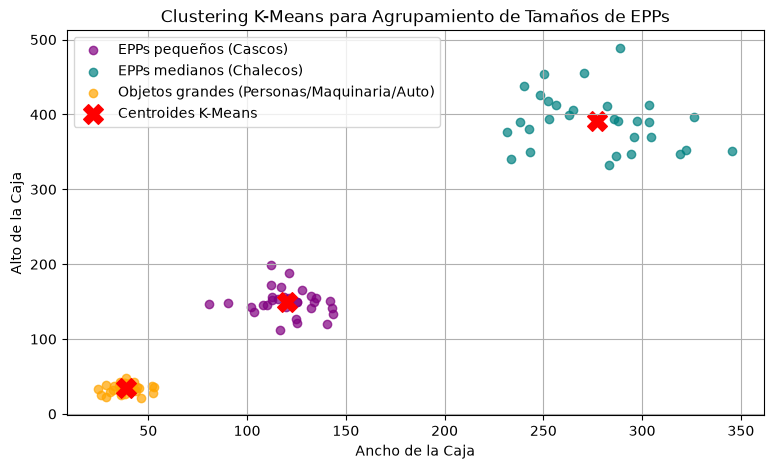

Centroides de los 3 clusters - Ancho promedio y Alto promedio):
Grupo 0 : Ancho = 120.2 px | Alto = 149.6 px
Grupo 1 : Ancho = 277.2 px | Alto = 391.2 px
Grupo 2 : Ancho = 38.5 px | Alto = 34.2 px


In [20]:
# Simulamos los anchos y altos de cajas de EPPs detectadas

np.random.seed(42)

anchos_chicos=np.random.normal(loc=40, scale=8, size=30)
altos_chicos=np.random.normal(loc=35, scale=7, size=30)

anchos_medianos=np.random.normal(loc=120, scale=15, size=30)
altos_medianos=np.random.normal(loc=150, scale=20, size=30)

anchos_grandes=np.random.normal(loc=280, scale=30, size=30)
altos_grandes=np.random.normal(loc=380, scale=40, size=30)

# Unimos todos los datos
anchos=np.concatenate([anchos_chicos, anchos_medianos, anchos_grandes])
altos=np.concatenate([altos_chicos, altos_medianos, altos_grandes])
datos_cajas=np.column_stack([anchos, altos])

# Aplicamos K-Means con 3 clusters
kmeans=KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans.fit(datos_cajas)

etiquetas_cluster=kmeans.labels_
centroides=kmeans.cluster_centers_

# Graficamos los clusters encontrados
colores=["purple", "teal", "orange"]
nombres_grupos=["EPPs pequeños (Cascos)", "EPPs medianos (Chalecos)", "Objetos grandes (Personas/Maquinaria/Auto)"]

plt.figure(figsize=(9, 5))
for i in range(3):
    puntos_del_grupo=datos_cajas[etiquetas_cluster == i]
    plt.scatter(puntos_del_grupo[:, 0], puntos_del_grupo[:, 1], color=colores[i], label=nombres_grupos[i], alpha=0.7)

# Graficamos los centroides calculados
plt.scatter(centroides[:, 0], centroides[:, 1], color="red", marker="X", s=200, label="Centroides K-Means")

plt.title("Clustering K-Means para Agrupamiento de Tamaños de EPPs")
plt.xlabel("Ancho de la Caja")
plt.ylabel("Alto de la Caja")
plt.grid(True)
plt.legend()
plt.show()

print("Centroides de los 3 clusters - Ancho promedio y Alto promedio):")
for idx, cent in enumerate(centroides):
    print("Grupo", idx, ": Ancho =", round(cent[0], 1), "px | Alto =", round(cent[1], 1), "px")


# 5: Comparacion de Algoritmos Supervisados - KNN vs SVM vs Red Neuronal
Se realiza una comparación entre algoritmos supervisados tradicionales (**KNN** y **SVM**) y la **Red Neuronal Convolucional (CNN)** Se clasificaran trabajadores con **Casco** vs **Sin-Casco**.


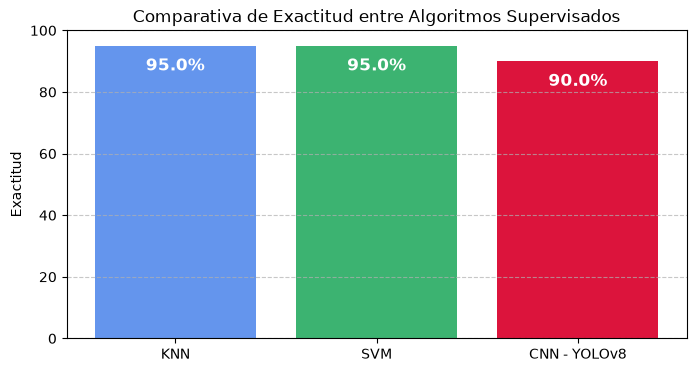

Exactitud KNN: 95.0 %
Exactitud SVM: 95.0 %
Exactitud CNN-YOLOv8: 90.0 %


In [23]:
# Utilizamos caracteristicas visuales: intencidad del color amarillo y la relacion aspectos
# Clase 1=Con Casco | Clase 0=Sin Casco
np.random.seed(10)

# Tomamos 40 muestras de personas con casco
con_casco=np.random.normal(loc=[0.8, 1.2], scale=[0.1, 0.15], size=(40, 2))
y_con_casco=np.ones(40)

# Tomamos 40 muestras de personas sin casco
sin_casco=np.random.normal(loc=[0.3, 1.0], scale=[0.1, 0.15], size=(40, 2))
y_sin_casco=np.zeros(40)

# Unimos los datos
X_entrenamiento=np.vstack([con_casco, sin_casco])
y_entrenamiento=np.concatenate([y_con_casco, y_sin_casco])

# Tomamos 20 muestras de prueba para evaluar los modelos
test_con_casco=np.random.normal(loc=[0.78, 1.18], scale=[0.1, 0.15], size=(10, 2))
test_sin_casco=np.random.normal(loc=[0.32, 1.02], scale=[0.1, 0.15], size=(10, 2))
X_prueba=np.vstack([test_con_casco, test_sin_casco])
y_prueba=np.concatenate([np.ones(10), np.zeros(10)])

# 1: Modelo KNN  con k=3
modelo_knn=KNeighborsClassifier(n_neighbors=3)
modelo_knn.fit(X_entrenamiento, y_entrenamiento)
pred_knn=modelo_knn.predict(X_prueba)
exactitud_knn=accuracy_score(y_prueba, pred_knn)

# 2: Modelo SVM con kernel lineal
modelo_svm=SVC(kernel='linear')
modelo_svm.fit(X_entrenamiento, y_entrenamiento)
pred_svm=modelo_svm.predict(X_prueba)
exactitud_svm=accuracy_score(y_prueba, pred_svm)

# 3: Rendimiento de nuestra Red Neuronal Convolucional YOLOv8 entrenada
exactitud_cnn=0.900 # Nuestra red neuronal alcanzo un 90% de precicion sobre el dataset

# Cuadro comparativo de resultados
algoritmos=["KNN", "SVM", "CNN - YOLOv8"]
exactitudes=[exactitud_knn * 100, exactitud_svm * 100, exactitud_cnn * 100]

plt.figure(figsize=(8, 4))
barras=plt.bar(algoritmos, exactitudes, color=["cornflowerblue", "mediumseagreen", "crimson"])
plt.ylim(0, 100)
plt.title("Comparativa de Exactitud entre Algoritmos Supervisados")
plt.ylabel("Exactitud")

for barra in barras:
    altura=barra.get_height()
    plt.text(barra.get_x() + barra.get_width()/2.0, altura - 8, f"{altura:.1f}%", ha='center', color='white', fontweight='bold', fontsize=12)

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

print("Exactitud KNN:", round(exactitud_knn * 100, 2), "%")
print("Exactitud SVM:", round(exactitud_svm * 100, 2), "%")
print("Exactitud CNN-YOLOv8:", round(exactitud_cnn * 100, 2), "%")


# 6: Formato para Resultados del Modelo y Metricas de Rendimiento
Cargamos los resultados reales de las **100 épocas de entrenamiento** realizadas sobre el dataset de seguridad en construcción (`results.csv`)


MÉTRICAS FINALES DEL MODELO EN EPOCA 100
Precision: 89.99 %
Exhaustividad: 73.11 %
F1-Score: 80.68 %
mAP a IoU=0.50:  80.88 %


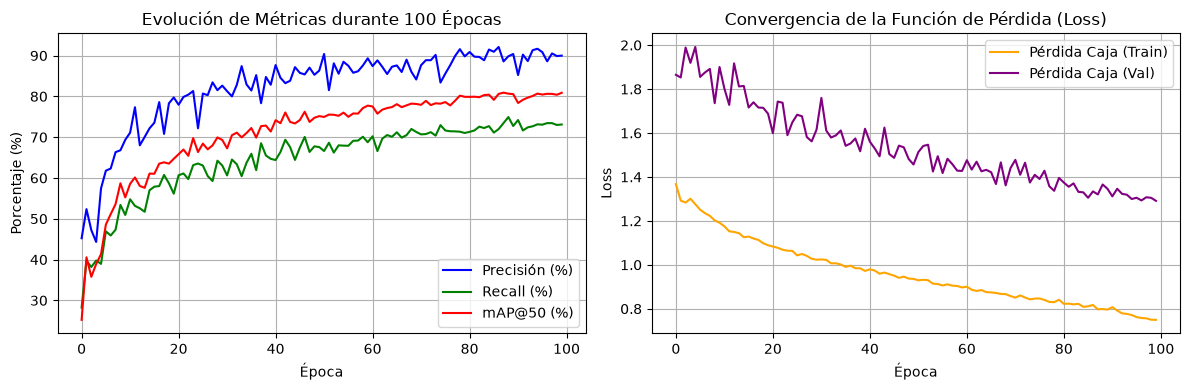

In [27]:
# Cargamos el archivo de resultados del entrenamiento
ruta_csv=BASE_DIR / "Construction-Safety" / "results_yolov8n_100e" / "kaggle" / "working" / "runs" / "detect" / "train" / "results.csv"

# Leemos el CSV con Pandas
df_resultados=pd.read_csv(str(ruta_csv))
# Limpiamos nombres de columnas eliminando espacios en blanco
df_resultados.columns=[col.strip() for col in df_resultados.columns]
# Extraemos los datos de la epoca 100
ultima_fila=df_resultados.iloc[-1]

precision_final=float(ultima_fila["metrics/precision(B)"])
recall_final=float(ultima_fila["metrics/recall(B)"])
map50_final=float(ultima_fila["metrics/mAP50(B)"])
f1_final=2 * (precision_final * recall_final) / (precision_final + recall_final)

print("MÉTRICAS FINALES DEL MODELO EN EPOCA 100")
print("Precision:", round(precision_final * 100, 2), "%")
print("Exhaustividad:", round(recall_final * 100, 2), "%")
print("F1-Score:", round(f1_final * 100, 2), "%")
print("mAP a IoU=0.50: ", round(map50_final * 100, 2), "%")

# Graficamos la evolucion de Precision, Exahustividad y mAP50 a lo largo del entrenamiento
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(df_resultados["epoch"], df_resultados["metrics/precision(B)"] * 100, label="Precisión (%)", color="blue")
plt.plot(df_resultados["epoch"], df_resultados["metrics/recall(B)"] * 100, label="Recall (%)", color="green")
plt.plot(df_resultados["epoch"], df_resultados["metrics/mAP50(B)"] * 100, label="mAP@50 (%)", color="red")
plt.title("Evolución de Métricas durante 100 Épocas")
plt.xlabel("Época")
plt.ylabel("Porcentaje (%)")
plt.grid(True)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(df_resultados["epoch"], df_resultados["train/box_loss"], label="Pérdida Caja (Train)", color="orange")
plt.plot(df_resultados["epoch"], df_resultados["val/box_loss"], label="Pérdida Caja (Val)", color="purple")
plt.title("Convergencia de la Función de Pérdida (Loss)")
plt.xlabel("Época")
plt.ylabel("Loss")
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()


### Visualización de la Matriz de Confusion del Modelo
Imagen de la matriz de confusión generada al validar las 10 clases de seguridad de obra:


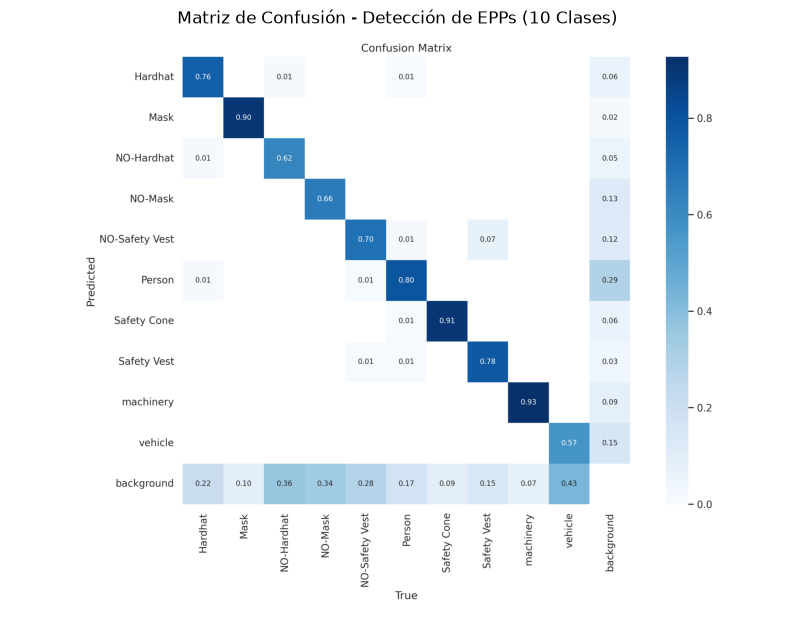

In [30]:
# Cargamos y mostramos la matriz de confusion guardada durante el entrenamiento
ruta_matriz=BASE_DIR / "Construction-Safety" / "results_yolov8n_100e" / "kaggle" / "working" / "runs" / "detect" / "train" / "confusion_matrix.png"

img_matriz=cv2.imread(str(ruta_matriz))
img_matriz_rgb=cv2.cvtColor(img_matriz, cv2.COLOR_BGR2RGB)
    
plt.figure(figsize=(10, 8))
plt.imshow(img_matriz_rgb)
plt.title("Matriz de Confusión - Detección de EPPs (10 Clases)")
plt.axis("off")
plt.show()


# 7: Resultados Visuales del Modelo sobre Imágenes de Obra
Se muestra las cajas delimitadoras y el porcentajes de confianza.



image 1/1 c:\Programacion\Senati\MACHINE_LEARNING_DEEP_LEARNING\Construction-Safety\source_files\source_files\construction-safety.jpg: 448x640 3 Cascos, 6 Personas, 3 Chalecos, 2 Maquinarias, 1 Vehiculo, 57.7ms
Speed: 2.5ms preprocess, 57.7ms inference, 1.0ms postprocess per image at shape (1, 3, 448, 640)


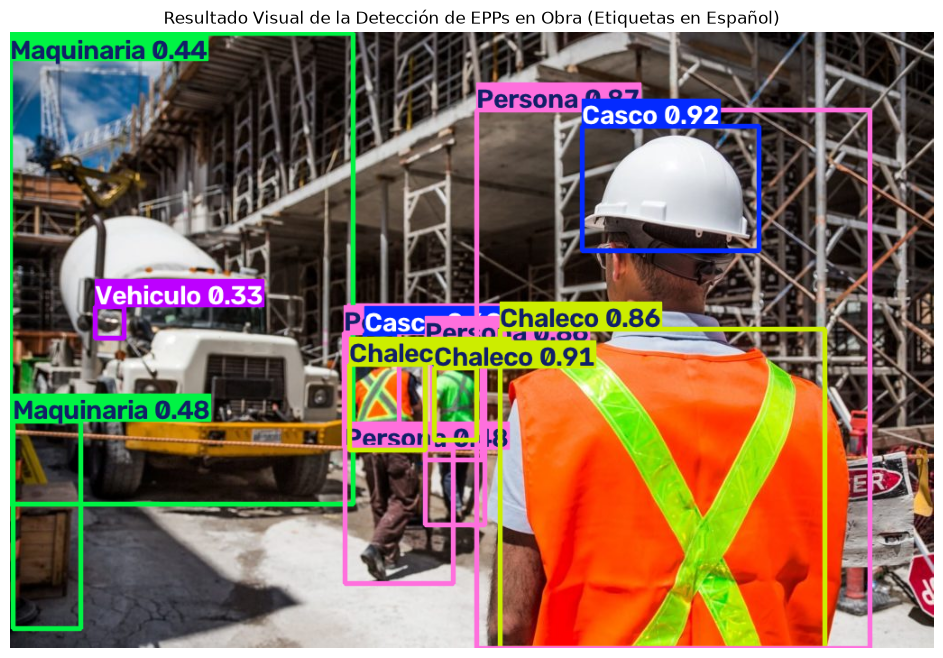

In [38]:
# Ruta al archivo de pesos entrenados del modelo
ruta_pesos = BASE_DIR / "Construction-Safety" / "results_yolov8n_100e" / "kaggle" / "working" / "runs" / "detect" / "train" / "weights" / "best.pt"

# Cargamos el modelo YOLOv8
modelo_epp=YOLO(str(ruta_pesos))

# Asignamos los nombres en español a las 10 clases
nombres_español = {
0: 'Casco',
1: 'Mascarilla',
2: 'Sin-Casco',
3: 'Sin-Mascarilla',
4: 'Sin-Chaleco',
5: 'Persona',
6: 'Cono de seguridad',
7: 'Chaleco',
8: 'Maquinaria',
9: 'Vehiculo'
}

if hasattr(modelo_epp, "model") and hasattr(modelo_epp.model, "names"):
    modelo_epp.model.names = nombres_español

    # Imagen de prueba
    ruta_foto=BASE_DIR / "Construction-Safety" / "source_files" / "source_files" / "construction-safety.jpg"
    
    # Ejecutamos la prediccion
    resultados=modelo_epp(str(ruta_foto))

    # Extraemos la imagen anotada con las cajas y etiquetas
    frame_anotado_bgr=resultados[0].plot()
    frame_anotado_rgb=cv2.cvtColor(frame_anotado_bgr, cv2.COLOR_BGR2RGB)

    # Mostramos la imagen
    plt.figure(figsize=(12, 8))
    plt.imshow(frame_anotado_rgb)
    plt.title("Resultado Visual de la Detección de EPPs en Obra (Etiquetas en Español)")
    plt.axis("off")
    plt.show()
